In [1]:
library(tidyverse)  # Data wrangling packages.

my_bucket <- Sys.getenv('WORKSPACE_BUCKET')

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
#load in PRS
name_of_file_in_bucket <- 'adjusted_PRS_scores0.csv'
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)
prs <- read_csv(name_of_file_in_bucket) 

colnames(prs)

character(0)

Rows: 135557 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma_adjusted_score, Afib_adjusted_score, BreastC_adj...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "person_id"                "Asthma_adjusted_score"   
 [3] "Afib_adjusted_score"      "BreastC_adjusted_score"  
 [5] "CKD_adjusted_score"       "CHD_adjusted_score"      
 [7] "HyperC_adjusted_score"    "ProstateC_adjusted_score"
 [9] "t1d_adjusted_score"       "t2d_adjusted_score"

In [3]:
#load in case/control
name_of_file_in_bucket <- 'Case_Control_df.csv'
system(paste0("gsutil cp gs://fc-secure-672eeb92-4859-4ed9-9f59-d4349f3534a0/notebooks/Case_Control_df.csv ."), intern=T)
Case_Control_df  <- read_csv(name_of_file_in_bucket)

colnames(Case_Control_df)

character(0)

Rows: 265954 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma, Afib, BreastC, CKD, CHD, HyperC, ProstateC, t2d...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "person_id" "Asthma"    "Afib"      "BreastC"   "CKD"       "CHD"      
 [7] "HyperC"    "ProstateC" "t2d"       "t1d"

In [4]:
#Merge
merged_df<-merge(prs, Case_Control_df, on="person_id")


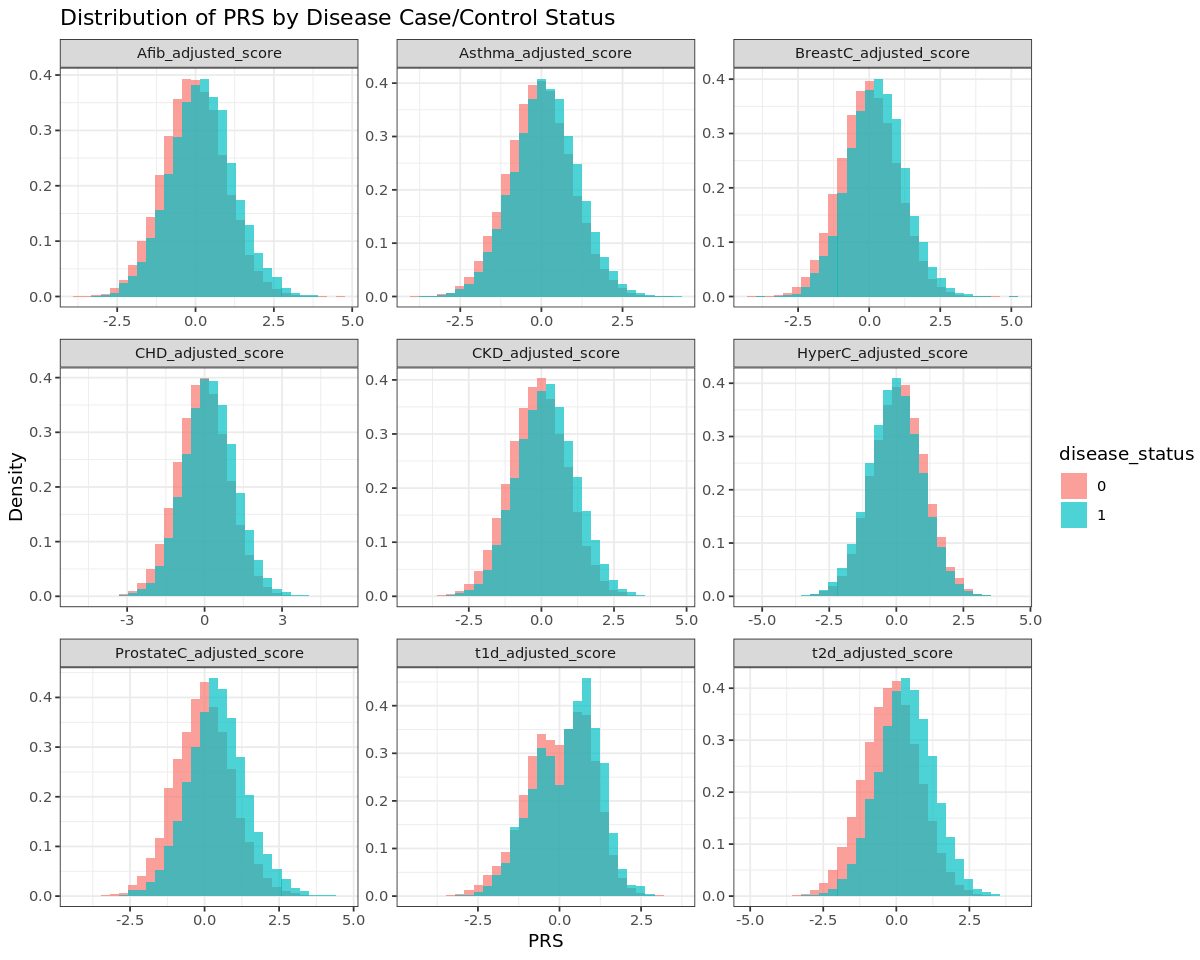

In [5]:
#Plot
diseases<-c("Asthma", "Afib", "BreastC", "CKD",
         "CHD", "HyperC", "ProstateC", "t1d", "t2d")

options(repr.plot.width = 10, repr.plot.height = 8)  # Set width and height

long_prs <- merged_df %>%
  pivot_longer(
    cols = contains("_adjusted_score"),  
    names_to = "PRS",                # Name for the new column holding the original column names with "_prs_zscore"
    values_to = "value"              # Name for the new column holding the values
  )


merged_data<-merge(long_prs, Case_Control_df, on="person_id", how="left")


# Convert relevant disease columns to factors
merged_data <- merged_data %>%
  mutate(across(all_of(diseases), as.factor))

# Pivot longer to create a new data frame in long format to include disease status
plot_data <- merged_data %>%
  pivot_longer(
    cols = all_of(diseases),
    names_to = "disease",
    values_to = "disease_status"
  )

plot_data<-plot_data[substr(plot_data$PRS, 1, nchar(plot_data$disease)) == plot_data$disease, ]

plot_data <- plot_data %>%
  drop_na()


# Generate a single plot with facets for each disease and PRS combination
ggplot(plot_data, aes(x = value, fill = disease_status)) +
  geom_histogram(aes(y = after_stat(density)), alpha = 0.7, bins = 30, position = "identity") +
  facet_wrap(~ PRS, scales = "free") +  # Facet grid by disease
  theme_bw() +
  labs(
    x = "PRS", 
    y = "Density", 
    title = "Distribution of PRS by Disease Case/Control Status"
  )

# Pre-adjusted results

In [9]:
# Define conditions and readable disease names
conditions <- c(
  "asthma",
  "atrial_fibrilation",
  "breast_cancer",
  "ckd",
  "coronary_heart_disease",
  "hypercholesterolemia",
  "prostate_cancer",
  "t1d",
  "t2d"
)

disease_labels <- c(
  "Asthma",
  "Afib",
  "BreastC",
  "CKD",
  "CHD",
  "HyperC",
  "ProstateC",
  "t1d",
  "t2d"
)


all_prs <- NULL


# Loop through all conditions
for (i in seq_along(conditions)) {
  condition <- conditions[i]
  disease <- disease_labels[i]
  
  # Define filename
  name_of_file_in_bucket <- paste0("combined_", condition, ".txt")
  
  # Download from GCS
  system(
    paste0(
      "gsutil cp gs://fc-secure-61ffe592-139f-4be1-8b47-8dbe2adbb1eb/data/",
      name_of_file_in_bucket,
      " ."
    ),
    intern = TRUE
  )
  
  # Read CSV
  prs <- read_csv(name_of_file_in_bucket, show_col_types = FALSE) |> select(1,4)
  
  # Add disease label and rename the score column
  prs <- prs %>%
  rename(!!paste0(disease, "_score") := 2) %>%
  rename("person_id" := 1)
  
  # Merge by IID
  if (is.null(all_prs)) {
    all_prs <- prs
  } else {
    all_prs <- merge(all_prs, prs, by = "person_id")
  }
}

#MERGE
merged_df<-merge(all_prs, Case_Control_df, on="person_id", how="inner")



In [10]:
head(merged_df)

,person_id,Asthma_score,Afib_score,BreastC_score,CKD_score,CHD_score,HyperC_score,ProstateC_score,t1d_score,t2d_score,Asthma,Afib,BreastC,CKD,CHD,HyperC,ProstateC,t2d,t1d
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1000000,2.46232e-05,0.539840,0.055497500,5.72415e-06,-1.15270e-03,0.000133829,1.022480,0.703158,1.07672e-05,0,NA,NA,NA,0,NA,NA,NA,NA
2,1000004,1.64795e-05,0.457669,0.078198100,-1.85106e-06,4.59028e-04,0.000971121,1.024710,0.216447,2.38353e-06,NA,1,NA,NA,0,0,0,NA,NA
3,1000033,1.44070e-05,0.454620,-0.000638461,-5.06045e-06,1.16849e-03,0.000057056,0.955817,0.767286,2.45168e-06,NA,NA,NA,NA,1,NA,NA,NA,NA
4,1000039,2.35521e-05,0.532715,0.056495900,1.27856e-05,3.30262e-05,0.000999450,1.052610,0.352566,1.12626e-05,0,NA,0,0,0,NA,NA,NA,NA
5,1000042,2.20225e-05,0.575750,0.021932600,1.62579e-06,-1.16439e-03,-0.000137928,0.993300,0.382763,9.85336e-06,NA,1,0,NA,1,1,0,NA,NA
6,1000045,1.92441e-05,0.463480,0.053716000,-3.62927e-06,-7.93505e-04,-0.001351900,0.984889,1.288880,4.37578e-06,NA,NA,0,NA,0,NA,NA,NA,NA


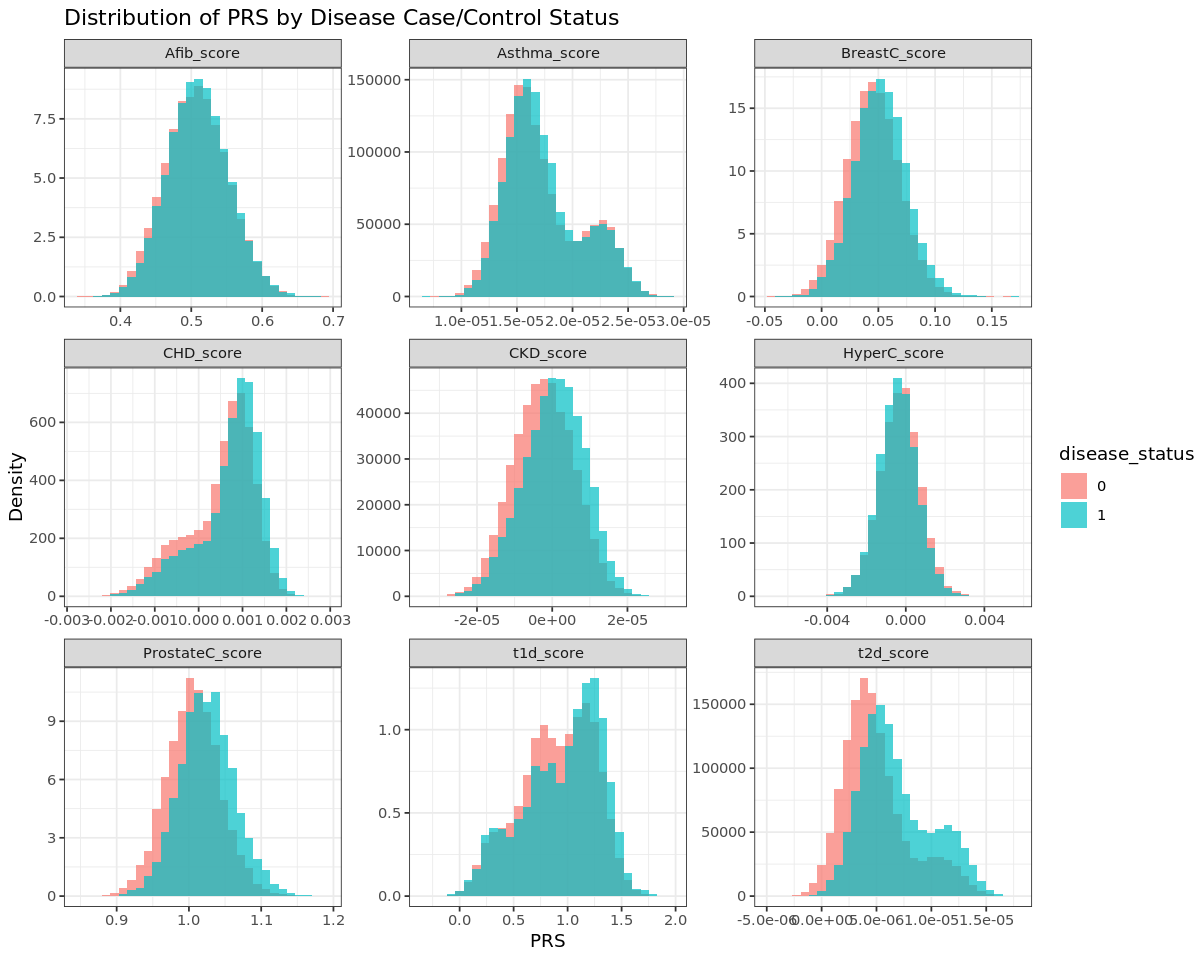

In [11]:
#Plot

long_prs <- merged_df %>%
  pivot_longer(
    cols = contains("_score"),  
    names_to = "PRS",                # Name for the new column holding the original column names with "_prs_zscore"
    values_to = "value"              # Name for the new column holding the values
  )


merged_data<-merge(long_prs, Case_Control_df, on="person_id", how="left")


# Convert relevant disease columns to factors
merged_data <- merged_data %>%
  mutate(across(all_of(diseases), as.factor))

# Pivot longer to create a new data frame in long format to include disease status
plot_data <- merged_data %>%
  pivot_longer(
    cols = all_of(diseases),
    names_to = "disease",
    values_to = "disease_status"
  )

plot_data<-plot_data[substr(plot_data$PRS, 1, nchar(plot_data$disease)) == plot_data$disease, ]

plot_data <- plot_data %>%
  drop_na()


# Generate a single plot with facets for each disease and PRS combination
ggplot(plot_data, aes(x = value, fill = disease_status)) +
  geom_histogram(aes(y = after_stat(density)), alpha = 0.7, bins = 30, position = "identity") +
  facet_wrap(~ PRS, scales = "free") +  # Facet grid by disease
  theme_bw() +
  labs(
    x = "PRS", 
    y = "Density", 
    title = "Distribution of PRS by Disease Case/Control Status"
  )